# Final report



In [1]:
import jax
import jax.numpy as jnp
import numpy as np
import matplotlib.pyplot as plt
from jaxopt import AndersonAcceleration
import pickle
import seaborn as sns


In [2]:
# Naka-Rushton function

def nr(x, n):
    """Naka-Rushton activation function"""
    x = jnp.maximum(x, 0.0)
    return jnp.power(x, n) / (jnp.power(x, n) + 1)

In [3]:
def unpack_theta(theta, m):
    w_osn_r = jnp.array([theta[0], theta[0]])
    w_osn_b = jnp.array([theta[1], theta[1]])
    w_osn_g = jnp.array([theta[2], theta[2]])
    w_osn_y = jnp.array([theta[3], theta[3]])
    w_b_r = jnp.array([theta[4], theta[4]])
    w_b_g = jnp.array([theta[5], theta[5]])
    w_b_y = jnp.array([theta[6], theta[6]])
    w_r_y = jnp.array([theta[7], theta[7]])
    w_r_g = jnp.array([theta[8], theta[8]])
    alpha = jnp.array([theta[9], theta[9]])
    # Build 2x2 matrices so all elements are same type (avoids JAX shape error)
    zero = jnp.asarray(0.0)
    wr = jnp.asarray(theta[10])
    wy = jnp.asarray(theta[11])
    W_g_r = jnp.stack([jnp.stack([zero, wr]), jnp.stack([wr, zero])])
    W_g_y = jnp.stack([jnp.stack([zero, wy]), jnp.stack([wy, zero])])
    return w_osn_r, w_osn_b, w_osn_g, w_osn_y, w_b_r, w_b_g, w_b_y, w_r_y, w_r_g, alpha, W_g_r, W_g_y


# Fixed-point function for green neurons with different n values
def mitral_fixed_point(g, x, w_osn_r, w_osn_b, w_osn_g, w_b_r, w_b_g, W_g_r, w_r_g, alpha, n_r, n_b, n_g):
    """Fixed point equation for green neurons with different n values"""
    b_input = w_osn_b * alpha * x
    b_out = nr(b_input, n=n_b)

    r_input = w_osn_r * alpha * x - w_b_r * b_out - W_g_r @ g
    r_out = nr(r_input, n=n_r)

    g_input = w_osn_g * alpha * x - w_b_g * b_out + w_r_g * r_out
    g_new = nr(g_input, n=n_g)

    return g_new

# Solve fixed point via Anderson Acceleration with different n values
def solve_fixed_point(theta, x, m, n_r, n_b, n_g):
    w_osn_r, w_osn_b, w_osn_g, w_osn_y, w_b_r, w_b_g, w_b_y, w_r_y, w_r_g, alpha, W_g_r, W_g_y = unpack_theta(theta, m)
    g0 = jnp.zeros(m)

    # Create a function with the n values baked in that matches AndersonAcceleration signature
    def fixed_point_with_n(g, x, w_osn_r, w_osn_b, w_osn_g, w_b_r, w_b_g, W_g_r, w_r_g, alpha):
        return mitral_fixed_point(g, x, w_osn_r, w_osn_b, w_osn_g, w_b_r, w_b_g, W_g_r, w_r_g, alpha, n_r, n_b, n_g)

    aa = AndersonAcceleration(fixed_point_with_n, history_size=5, tol=1e-10, maxiter=50)
    solution = aa.run(g0, x, w_osn_r, w_osn_b, w_osn_g, w_b_r, w_b_g, W_g_r, w_r_g, alpha)
    return solution.params

# Compute mitral output with different n values
def mitral_output(theta, x, m, n_r, n_b, n_g, n_y):
    w_osn_r, w_osn_b, w_osn_g, w_osn_y, w_b_r, w_b_g, w_b_y, w_r_y, w_r_g, alpha, W_g_r, W_g_y = unpack_theta(theta, m)

    g = solve_fixed_point(theta, x, m, n_r, n_b, n_g)
    b = nr(w_osn_b * alpha * x, n=n_b)
    r = nr(w_osn_r * alpha * x - w_b_r * b - W_g_r @ g, n=n_r)
    y = nr(w_osn_y * alpha * x - w_b_y * b - W_g_y @ g + w_r_y * r, n=n_y)

    return r, g, b, y

In [10]:
n_r = 1.850
n_g = 1.868
n_b = 0.642
n_y = 1.562

m = 2
x = jnp.ones(m)  # input odour signal

## 8. Stepping along sparse directions in parameter space



In [11]:
# Load theta_opt from pickle file
theta_opt_file = 'Theta_opt/theta_opt_626_samples_n_different.pkl'
with open(theta_opt_file, 'rb') as f:
    theta_opt = pickle.load(f)

theta_opt = np.array(theta_opt)
initial_count = theta_opt.shape[0]  # Store initial count for summary
print(f"Loaded theta_opt with shape: {theta_opt.shape}")
print(f"Number of samples: {theta_opt.shape[0]}")
print(f"Number of parameters per sample: {theta_opt.shape[1]}")

Loaded theta_opt with shape: (626, 12)
Number of samples: 626
Number of parameters per sample: 12


In [35]:

U_A_sorted = np.load('reps_aligned_A.npz')['rep_A_sorted']
U_B_aligned = np.load('reps_aligned_B.npz')['rep_B_aligned']

# Aligned reps may be (13, k) while mitral theta has 12 weights — slice rows to match theta_opt
n_theta = int(theta_opt.shape[1])
U_A = np.asarray(U_A_sorted, dtype=float)[:n_theta, :]
U_B = np.asarray(U_B_aligned, dtype=float)[:n_theta, :]


The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


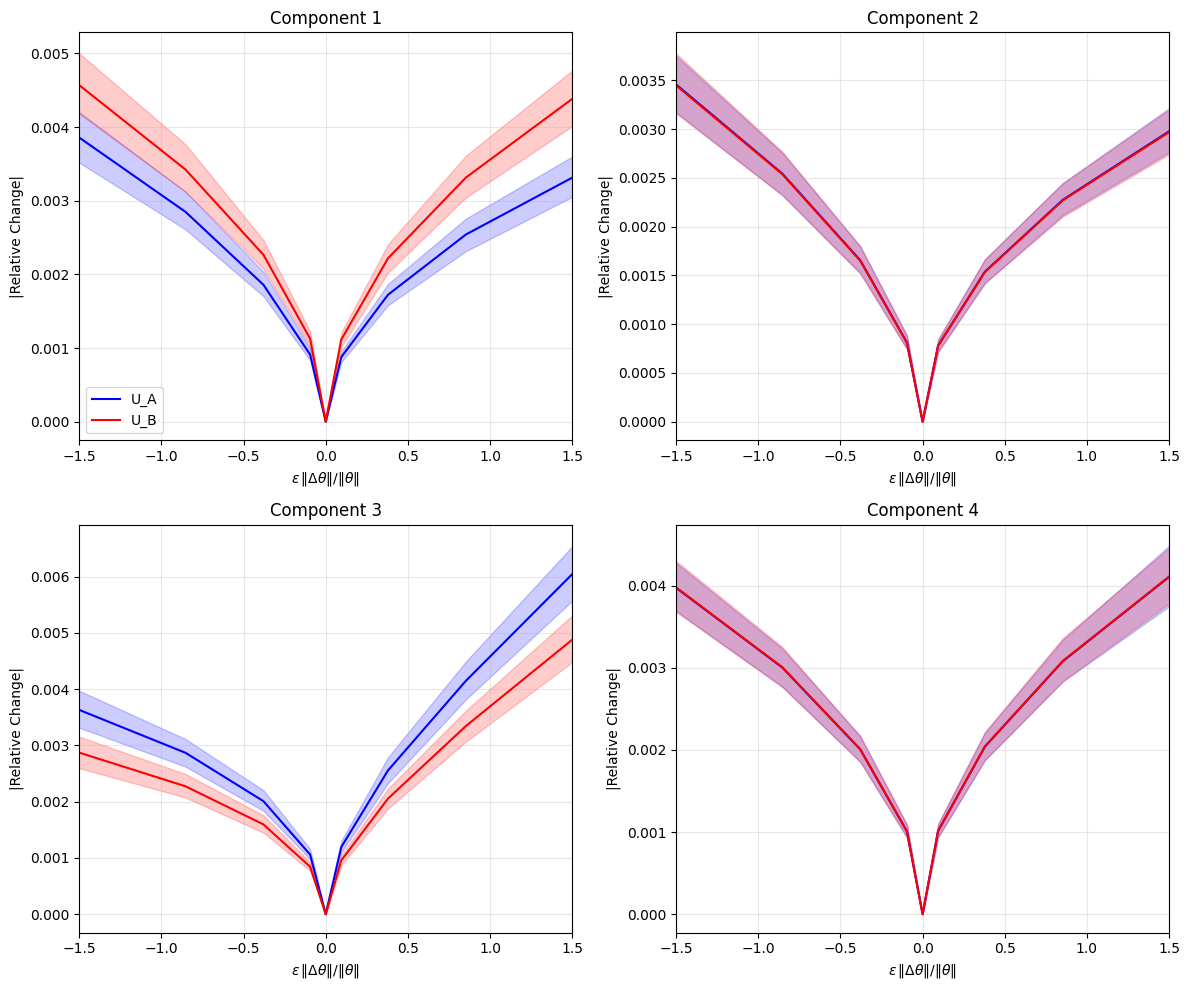

In [36]:
e = np.arange(-2, 2+0.2, 0.5)
n_samples = 626

theta_opt_subset = jnp.array(theta_opt[:n_samples])

def _mitral_single(theta):
    return mitral_output(theta, x, m, n_r, n_b, n_g, n_y)

mitral_output_batch = jax.jit(jax.vmap(_mitral_single))

_, _, _, y_baseline = mitral_output_batch(theta_opt_subset)
y_baseline = np.array(y_baseline)

norm_theta_all = np.linalg.norm(theta_opt_subset, axis=1)
mean_norm_theta = np.mean(norm_theta_all)

Us = [U_A, U_B]
u_labels = ['U_A', 'U_B']
u_colors = ['blue', 'red']
n_components = Us[0].shape[1]

n_rows = int(np.ceil(n_components / 2))
fig, axes = plt.subplots(n_rows, 2, figsize=(12, 5 * n_rows))
axes = np.atleast_1d(axes).flatten()
for j in range(n_components, len(axes)):
    axes[j].set_visible(False)

for M, u_label, color in zip(Us, u_labels, u_colors):
    for k in range(n_components):
        true_dir = jnp.array(M[:, k])
        true_dir = true_dir / jnp.linalg.norm(true_dir)

        y_save = []
        for i in range(len(e)):
            theta_step = theta_opt_subset + e[i] * true_dir
            _, _, _, y = mitral_output_batch(theta_step)
            y_save.append(np.array(y))
        y_array = np.array(y_save)

        theta_ratio = np.array([e[i] * (np.linalg.norm(e[i] * true_dir) / mean_norm_theta) for i in range(len(e))])
        y0_baseline = y_baseline[:, 0]
        rel0 = np.where(np.abs(y0_baseline) > 1e-12,
                        (y_array[:, :, 0] - y0_baseline) / y0_baseline,
                        y_array[:, :, 0] - y0_baseline)
        abs_rel0 = np.abs(rel0)
        theta_ratio_expanded = np.repeat(theta_ratio, n_samples)

        a = axes[k]
        sns.lineplot(x=theta_ratio_expanded, y=abs_rel0.ravel(), ax=a, color=color, label=u_label, errorbar=('ci', 95), legend=False)

n_cols = 2
for k in range(n_components):
    row, col = divmod(k, n_cols)
    if row == n_rows - 1:
        axes[k].set_xlabel(r'$\epsilon \, \|\Delta \theta\| / \|\theta\|$')
    if col == 0:
        axes[k].set_ylabel('|Relative Change|')
    axes[k].set_title(f'Component {k+1}')
    axes[k].grid(True, alpha=0.3)
    axes[k].set_xlim(-1.5, 1.5)
axes[0].legend()

plt.tight_layout()
plt.savefig('Figures_final/e_stepping_along_directions_A_B.eps')
plt.show()

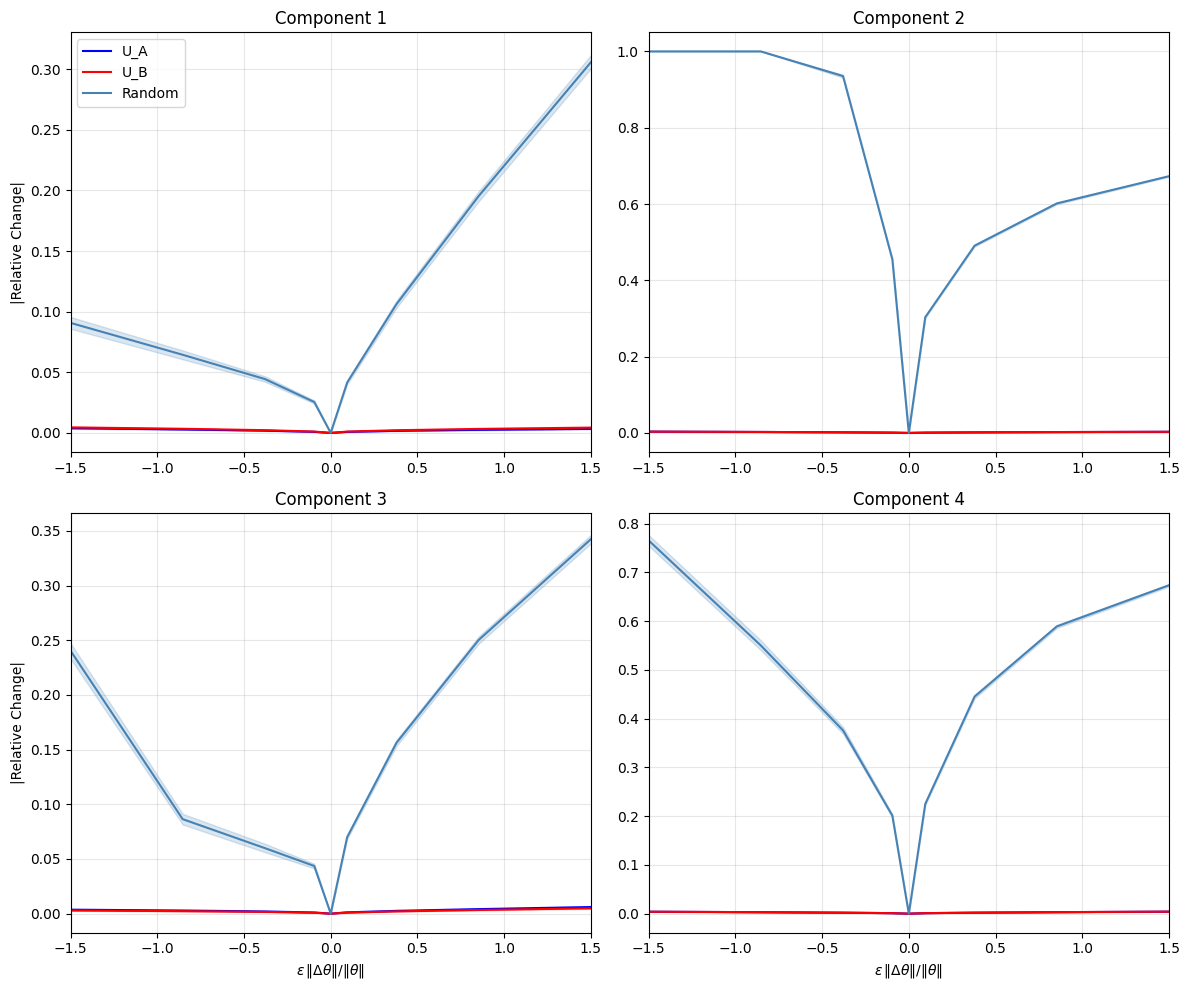

In [39]:
e = np.arange(-2, 2+0.2, 0.5)
n_samples = 626

theta_opt_subset = jnp.array(theta_opt[:n_samples])
key = jax.random.PRNGKey(0)

def _mitral_single(theta):
    return mitral_output(theta, x, m, n_r, n_b, n_g, n_y)

mitral_output_batch = jax.jit(jax.vmap(_mitral_single))

_, _, _, y_baseline = mitral_output_batch(theta_opt_subset)
y_baseline = np.array(y_baseline)

norm_theta_all = np.linalg.norm(theta_opt_subset, axis=1)
mean_norm_theta = np.mean(norm_theta_all)

Us = [U_A, U_B]
u_labels = ['U_A', 'U_B']
u_colors = ['blue', 'red']
n_components = Us[0].shape[1]

n_rows = int(np.ceil(n_components / 2))
fig, axes = plt.subplots(n_rows, 2, figsize=(12, 5 * n_rows))
axes = np.atleast_1d(axes).flatten()
for j in range(n_components, len(axes)):
    axes[j].set_visible(False)

for k in range(n_components):
    key, subkey = jax.random.split(key)
    random_dir = jax.random.normal(subkey, (Us[0].shape[0],))
    random_dir = random_dir / jnp.linalg.norm(random_dir)

    directions = []
    for M, u_label, color in zip(Us, u_labels, u_colors):
        true_dir = jnp.array(M[:, k])
        true_dir = true_dir / jnp.linalg.norm(true_dir)
        directions.append((u_label, true_dir, color))
    directions.append(('Random', random_dir, 'steelblue'))

    for label, direction, color in directions:
        y_save = []
        for i in range(len(e)):
            theta_step = theta_opt_subset + e[i] * direction
            _, _, _, y = mitral_output_batch(theta_step)
            y_save.append(np.array(y))
        y_array = np.array(y_save)

        theta_ratio = np.array([e[i] * (np.linalg.norm(e[i] * direction) / mean_norm_theta) for i in range(len(e))])
        y0_baseline = y_baseline[:, 0]
        rel0 = np.where(np.abs(y0_baseline) > 1e-12,
                        (y_array[:, :, 0] - y0_baseline) / y0_baseline,
                        y_array[:, :, 0] - y0_baseline)
        abs_rel0 = np.abs(rel0)
        theta_ratio_expanded = np.repeat(theta_ratio, n_samples)

        sns.lineplot(x=theta_ratio_expanded, y=abs_rel0.ravel(), ax=axes[k],
                     color=color, label=label, errorbar=('ci', 95), legend=False)

n_cols = 2
for k in range(n_components):
    row, col = divmod(k, n_cols)
    if row == n_rows - 1:
        axes[k].set_xlabel(r'$\epsilon \, \|\Delta \theta\| / \|\theta\|$')
    if col == 0:
        axes[k].set_ylabel('|Relative Change|')
    axes[k].set_title(f'Component {k+1}')
    axes[k].grid(True, alpha=0.3)
    axes[k].set_xlim(-1.5, 1.5)
axes[0].legend()

plt.tight_layout()
plt.show()